# Restaurant Sales and Menu Performance Analysis

## Project Overview

This project analyzes restaurant order data and menu data to understand sales performance, customer ordering patterns, top-performing menu items, low-performing menu items, category performance, and possible business recommendations.

The project uses two datasets:

- `order_details.csv`: contains order-level transaction records.
- `menu_items.csv`: contains menu item names, categories, and prices.

## Key Questions

1. What is the total revenue generated by the restaurant?
2. Which menu categories generate the most revenue?
3. Which menu items sell the most by quantity?
4. Which menu items generate the highest revenue?
5. Are the best-selling items also the highest revenue items?
6. What days and hours have the highest sales?
7. What items are commonly bought together?
8. Which low-performing items may need promotion, improvement, or removal?
9. What business recommendations can be made from the analysis?

## 1. Import Libraries

The libraries below will be used for data cleaning, analysis, and visualization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
from pathlib import Path

%matplotlib inline

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:,.2f}'.format)

## 2. Load the Datasets

The two input CSVs are in the repository’s `data/raw/` directory.

- `order_details.csv`
- `menu_items.csv`

In [2]:
# File paths
repo_root = Path.cwd() if (Path.cwd() / 'data' / 'raw').is_dir() else Path.cwd().parent
order_path = repo_root / 'data' / 'raw' / 'order_details.csv'
menu_path = repo_root / 'data' / 'raw' / 'menu_items.csv'

# Load datasets
orders = pd.read_csv(order_path)
menu = pd.read_csv(menu_path)

print('Orders shape:', orders.shape)
print('Menu shape:', menu.shape)

Orders shape: (12234, 5)
Menu shape: (32, 4)


In [3]:
orders.head()

,order_details_id,order_id,order_date,order_time,item_id
0,1,1,1/1/23,11:38:36 AM,109.00
1,2,2,1/1/23,11:57:40 AM,108.00
2,3,2,1/1/23,11:57:40 AM,124.00
3,4,2,1/1/23,11:57:40 AM,117.00
4,5,2,1/1/23,11:57:40 AM,129.00


In [4]:
menu.head()

,menu_item_id,item_name,category,price
0,101,Hamburger,American,12.95
1,102,Cheeseburger,American,13.95
2,103,Hot Dog,American,9.00
3,104,Veggie Burger,American,10.50
4,105,Mac & Cheese,American,7.00


## 3. Initial Data Inspection

This section checks column names, data types, missing values, and duplicate records.

In [5]:
print('ORDER DETAILS INFO')
orders.info()

print('\nMENU ITEMS INFO')
menu.info()

ORDER DETAILS INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12234 entries, 0 to 12233
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_details_id  12234 non-null  int64  
 1   order_id          12234 non-null  int64  
 2   order_date        12234 non-null  object 
 3   order_time        12234 non-null  object 
 4   item_id           12097 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 478.0+ KB

MENU ITEMS INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   menu_item_id  32 non-null     int64  
 1   item_name     32 non-null     object 
 2   category      32 non-null     object 
 3   price         32 non-null     float64
dtypes: float64(1), int64(1), object(2)
memory usage: 1.1+ KB


In [6]:
# Missing values
missing_orders = orders.isna().sum().to_frame('missing_values')
missing_menu = menu.isna().sum().to_frame('missing_values')

print('Missing values in orders:')
display(missing_orders)

print('Missing values in menu:')
display(missing_menu)

Missing values in orders:


,missing_values
order_details_id,0
order_id,0
order_date,0
order_time,0
item_id,137


Missing values in menu:


,missing_values
menu_item_id,0
item_name,0
category,0
price,0


In [7]:
print('Duplicate rows in orders:', orders.duplicated().sum())
print('Duplicate rows in menu:', menu.duplicated().sum())

Duplicate rows in orders: 0
Duplicate rows in menu: 0


### Data Quality Note

The `order_details` table contains some missing `item_id` values. These rows cannot be matched with menu item names, categories, or prices.

For business and revenue analysis, rows with missing `item_id` will be excluded because their item price is unknown. However, they can still be mentioned as a data quality issue in the final report.

## 4. Data Cleaning and Preparation

The cleaning steps include:

- Converting date and time columns to proper datetime format.
- Merging order details with menu item information.
- Creating new useful columns such as revenue, month, weekday, and hour.
- Separating rows that can be used for revenue analysis from rows with missing item information.

In [8]:
# Make copies of the original datasets
orders_clean = orders.copy()
menu_clean = menu.copy()

# Convert order_date to datetime
orders_clean['order_date'] = pd.to_datetime(orders_clean['order_date'], format='%m/%d/%y')

# Convert order_time to datetime time format
orders_clean['order_time'] = pd.to_datetime(orders_clean['order_time'], format='%I:%M:%S %p').dt.time

# Create a combined datetime column
orders_clean['order_datetime'] = pd.to_datetime(
    orders_clean['order_date'].astype(str) + ' ' + orders_clean['order_time'].astype(str)
)

# Convert item_id to nullable integer type
orders_clean['item_id'] = orders_clean['item_id'].astype('Int64')

orders_clean.head()

,order_details_id,order_id,order_date,order_time,item_id,order_datetime
0,1,1,2023-01-01,11:38:36,109,2023-01-01 11:38:36
1,2,2,2023-01-01,11:57:40,108,2023-01-01 11:57:40
2,3,2,2023-01-01,11:57:40,124,2023-01-01 11:57:40
3,4,2,2023-01-01,11:57:40,117,2023-01-01 11:57:40
4,5,2,2023-01-01,11:57:40,129,2023-01-01 11:57:40


In [9]:
# Merge order details with menu items
# Left join keeps all order rows, including those with missing or unmatched item IDs.
df = orders_clean.merge(
    menu_clean,
    left_on='item_id',
    right_on='menu_item_id',
    how='left'
)

print('Merged dataset shape:', df.shape)
df.head()

Merged dataset shape: (12234, 10)


,order_details_id,order_id,order_date,order_time,item_id,order_datetime,menu_item_id,item_name,category,price
0,1,1,2023-01-01,11:38:36,109,2023-01-01 11:38:36,109.00,Korean Beef Bowl,Asian,17.95
1,2,2,2023-01-01,11:57:40,108,2023-01-01 11:57:40,108.00,Tofu Pad Thai,Asian,14.50
2,3,2,2023-01-01,11:57:40,124,2023-01-01 11:57:40,124.00,Spaghetti,Italian,14.50
3,4,2,2023-01-01,11:57:40,117,2023-01-01 11:57:40,117.00,Chicken Burrito,Mexican,12.95
4,5,2,2023-01-01,11:57:40,129,2023-01-01 11:57:40,129.00,Mushroom Ravioli,Italian,15.50


In [10]:
# Check rows without matched menu information
unmatched_rows = df[df['menu_item_id'].isna()]
print('Rows without matched menu information:', len(unmatched_rows))

unmatched_rows.head()

Rows without matched menu information: 137


,order_details_id,order_id,order_date,order_time,item_id,order_datetime,menu_item_id,item_name,category,price
121,122,50,2023-01-01,18:41:01,<NA>,2023-01-01 18:41:01,NaN,NaN,NaN,NaN
297,298,125,2023-01-02,20:31:06,<NA>,2023-01-02 20:31:06,NaN,NaN,NaN,NaN
357,358,147,2023-01-03,14:32:51,<NA>,2023-01-03 14:32:51,NaN,NaN,NaN,NaN
386,387,161,2023-01-03,16:43:46,<NA>,2023-01-03 16:43:46,NaN,NaN,NaN,NaN
469,470,200,2023-01-03,22:24:05,<NA>,2023-01-03 22:24:05,NaN,NaN,NaN,NaN


In [11]:
# Create analysis dataset by removing rows without matched menu details
analysis_df = df.dropna(subset=['menu_item_id']).copy()

# Convert menu_item_id to integer after removing missing rows
analysis_df['menu_item_id'] = analysis_df['menu_item_id'].astype(int)

# Revenue per row is the item price because each row represents one ordered item
analysis_df['revenue'] = analysis_df['price']

# Create time-based columns
analysis_df['date'] = analysis_df['order_datetime'].dt.date
analysis_df['month'] = analysis_df['order_datetime'].dt.month_name()
analysis_df['month_number'] = analysis_df['order_datetime'].dt.month
analysis_df['day_name'] = analysis_df['order_datetime'].dt.day_name()
analysis_df['day_number'] = analysis_df['order_datetime'].dt.dayofweek
analysis_df['hour'] = analysis_df['order_datetime'].dt.hour

print('Rows available for revenue analysis:', analysis_df.shape[0])
analysis_df.head()

Rows available for revenue analysis: 12097


,order_details_id,order_id,order_date,order_time,item_id,order_datetime,menu_item_id,item_name,category,price,revenue,date,month,month_number,day_name,day_number,hour
0,1,1,2023-01-01,11:38:36,109,2023-01-01 11:38:36,109,Korean Beef Bowl,Asian,17.95,17.95,2023-01-01,January,1,Sunday,6,11
1,2,2,2023-01-01,11:57:40,108,2023-01-01 11:57:40,108,Tofu Pad Thai,Asian,14.50,14.50,2023-01-01,January,1,Sunday,6,11
2,3,2,2023-01-01,11:57:40,124,2023-01-01 11:57:40,124,Spaghetti,Italian,14.50,14.50,2023-01-01,January,1,Sunday,6,11
3,4,2,2023-01-01,11:57:40,117,2023-01-01 11:57:40,117,Chicken Burrito,Mexican,12.95,12.95,2023-01-01,January,1,Sunday,6,11
4,5,2,2023-01-01,11:57:40,129,2023-01-01 11:57:40,129,Mushroom Ravioli,Italian,15.50,15.50,2023-01-01,January,1,Sunday,6,11


## 5. Key Performance Indicators

This section calculates the main business KPIs for the restaurant.

In [12]:
total_revenue = analysis_df['revenue'].sum()
total_orders = analysis_df['order_id'].nunique()
total_items_sold = analysis_df.shape[0]
average_order_value = total_revenue / total_orders
average_items_per_order = total_items_sold / total_orders
start_date = analysis_df['order_datetime'].min().date()
end_date = analysis_df['order_datetime'].max().date()

kpi_summary = pd.DataFrame({
    'Metric': [
        'Start Date',
        'End Date',
        'Total Revenue',
        'Total Unique Orders',
        'Total Items Sold',
        'Average Order Value',
        'Average Items per Order',
        'Rows with Missing Item ID'
    ],
    'Value': [
        start_date,
        end_date,
        f'${total_revenue:,.2f}',
        f'{total_orders:,}',
        f'{total_items_sold:,}',
        f'${average_order_value:,.2f}',
        f'{average_items_per_order:,.2f}',
        f'{df["item_id"].isna().sum():,}'
    ]
})

kpi_summary

,Metric,Value
0,Start Date,2023-01-01
1,End Date,2023-03-31
2,Total Revenue,"$159,217.90"
3,Total Unique Orders,"5,343"
4,Total Items Sold,"12,097"
5,Average Order Value,$29.80
6,Average Items per Order,2.26
7,Rows with Missing Item ID,137


### KPI Interpretation

The KPIs give a quick overview of business performance. Total revenue shows the overall sales value, while average order value shows how much customers spend per order on average.

## 6. Monthly Sales Trend

This section checks how orders, quantity sold, and revenue changed from month to month.

In [13]:
monthly_sales = (
    analysis_df.groupby(['month_number', 'month'])
    .agg(
        orders=('order_id', 'nunique'),
        items_sold=('order_details_id', 'count'),
        revenue=('revenue', 'sum')
    )
    .reset_index()
    .sort_values('month_number')
)

monthly_sales

,month_number,month,orders,items_sold,revenue
0,1,January,1835,4104,"53,816.95"
1,2,February,1675,3851,"50,790.35"
2,3,March,1833,4142,"54,610.60"


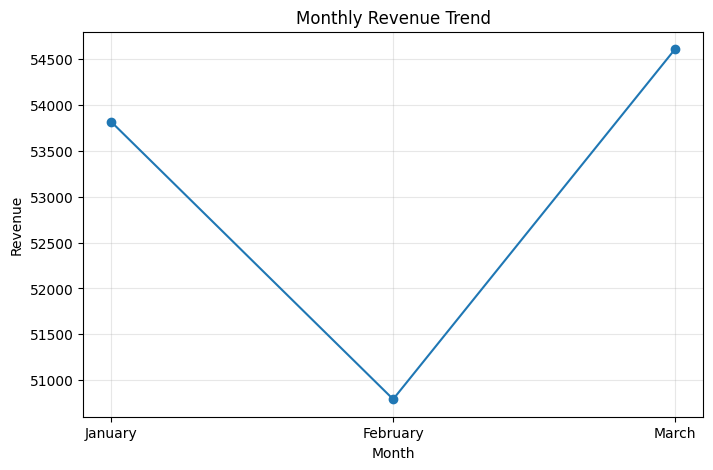

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(monthly_sales['month'], monthly_sales['revenue'], marker='o')
plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.grid(True, alpha=0.3)
plt.show()

In [15]:
# Average daily revenue by month gives a fairer comparison because months have different number of days.
daily_revenue = (
    analysis_df.groupby(['month_number', 'month', 'date'])
    .agg(revenue=('revenue', 'sum'))
    .reset_index()
)

avg_daily_revenue_by_month = (
    daily_revenue.groupby(['month_number', 'month'])
    .agg(avg_daily_revenue=('revenue', 'mean'))
    .reset_index()
    .sort_values('month_number')
)

avg_daily_revenue_by_month

,month_number,month,avg_daily_revenue
0,1,January,"1,736.03"
1,2,February,"1,813.94"
2,3,March,"1,761.63"


## 7. Category Performance

This section compares the restaurant's menu categories by sales quantity and revenue.

In [16]:
category_performance = (
    analysis_df.groupby('category')
    .agg(
        items_sold=('order_details_id', 'count'),
        unique_orders=('order_id', 'nunique'),
        revenue=('revenue', 'sum'),
        average_price=('price', 'mean')
    )
    .reset_index()
    .sort_values('revenue', ascending=False)
)

category_performance

,category,items_sold,unique_orders,revenue,average_price
2,Italian,2948,2292,"49,462.70",16.78
1,Asian,3470,2635,"46,720.65",13.46
3,Mexican,2945,2266,"34,796.80",11.82
0,American,2734,2152,"28,237.75",10.33


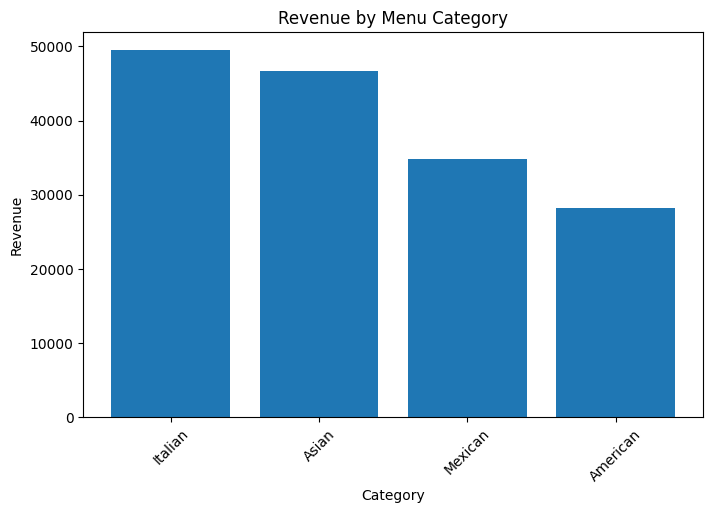

In [17]:
plt.figure(figsize=(8, 5))
plt.bar(category_performance['category'], category_performance['revenue'])
plt.title('Revenue by Menu Category')
plt.xlabel('Category')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.show()

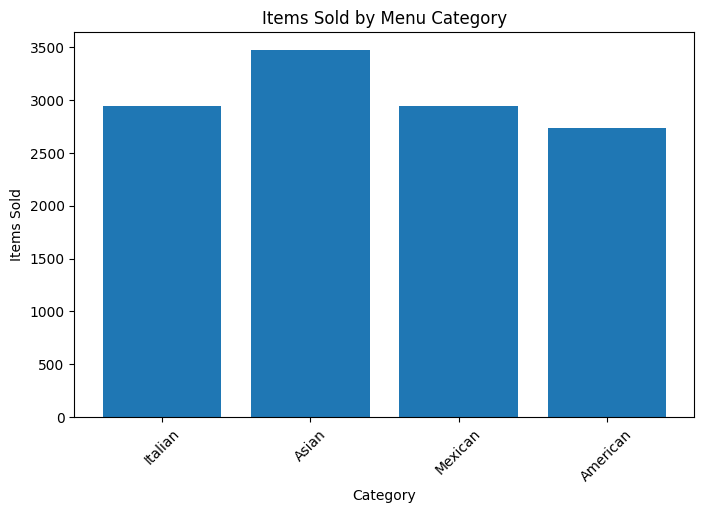

In [18]:
plt.figure(figsize=(8, 5))
plt.bar(category_performance['category'], category_performance['items_sold'])
plt.title('Items Sold by Menu Category')
plt.xlabel('Category')
plt.ylabel('Items Sold')
plt.xticks(rotation=45)
plt.show()

### Category Insight

This comparison helps show whether the category with the highest quantity sold is also the category with the highest revenue. A category may sell many items but generate less revenue if its items are cheaper.

## 8. Best-Selling Menu Items by Quantity

This section identifies the items customers bought most often.

In [19]:
top_items_quantity = (
    analysis_df.groupby(['item_name', 'category'])
    .agg(quantity_sold=('order_details_id', 'count'), revenue=('revenue', 'sum'), price=('price', 'mean'))
    .reset_index()
    .sort_values('quantity_sold', ascending=False)
)

top_items_quantity.head(10)

,item_name,category,quantity_sold,revenue,price
14,Hamburger,American,622,"8,054.90",12.95
10,Edamame,Asian,620,"3,100.00",5.00
16,Korean Beef Bowl,Asian,588,"10,554.60",17.95
3,Cheeseburger,American,583,"8,132.85",13.95
13,French Fries,American,571,"3,997.00",7.00
30,Tofu Pad Thai,Asian,562,"8,149.00",14.50
29,Steak Torta,Mexican,489,"6,821.55",13.95
26,Spaghetti & Meatballs,Italian,470,"8,436.50",17.95
17,Mac & Cheese,American,463,"3,241.00",7.00
9,Chips & Salsa,Mexican,461,"3,227.00",7.00


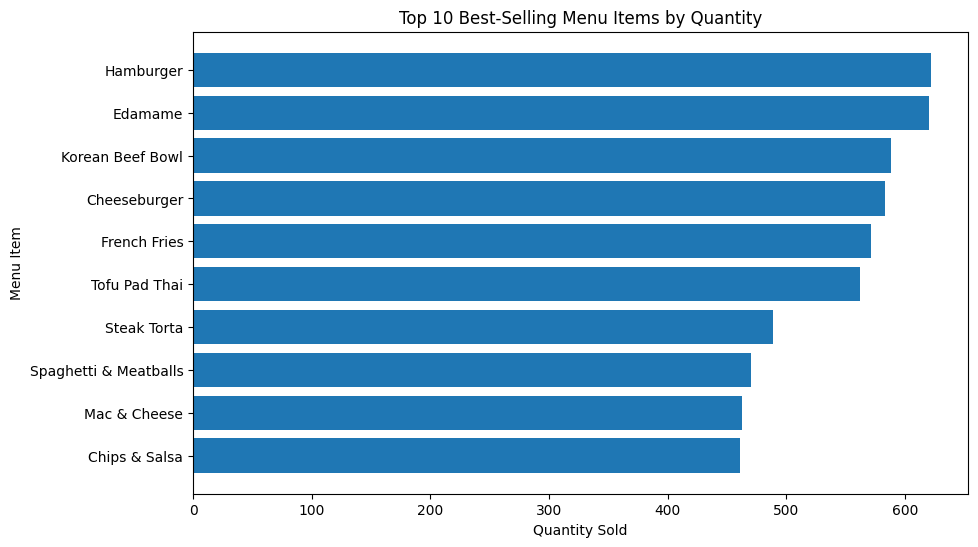

In [20]:
top_10_quantity = top_items_quantity.head(10).sort_values('quantity_sold')

plt.figure(figsize=(10, 6))
plt.barh(top_10_quantity['item_name'], top_10_quantity['quantity_sold'])
plt.title('Top 10 Best-Selling Menu Items by Quantity')
plt.xlabel('Quantity Sold')
plt.ylabel('Menu Item')
plt.show()

## 9. Top Menu Items by Revenue

This section identifies the items that brought in the most money.

In [21]:
top_items_revenue = (
    analysis_df.groupby(['item_name', 'category'])
    .agg(quantity_sold=('order_details_id', 'count'), revenue=('revenue', 'sum'), price=('price', 'mean'))
    .reset_index()
    .sort_values('revenue', ascending=False)
)

top_items_revenue.head(10)

,item_name,category,quantity_sold,revenue,price
16,Korean Beef Bowl,Asian,588,"10,554.60",17.95
26,Spaghetti & Meatballs,Italian,470,"8,436.50",17.95
30,Tofu Pad Thai,Asian,562,"8,149.00",14.50
3,Cheeseburger,American,583,"8,132.85",13.95
14,Hamburger,American,622,"8,054.90",12.95
20,Orange Chicken,Asian,456,"7,524.00",16.50
11,Eggplant Parmesan,Italian,420,"7,119.00",16.95
29,Steak Torta,Mexican,489,"6,821.55",13.95
5,Chicken Parmesan,Italian,364,"6,533.80",17.95
21,Pork Ramen,Asian,360,"6,462.00",17.95


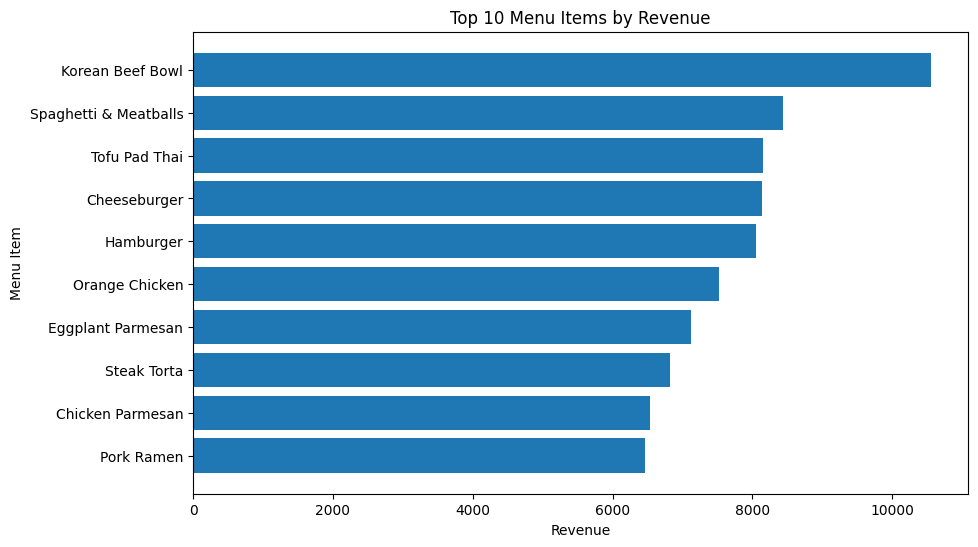

In [22]:
top_10_revenue = top_items_revenue.head(10).sort_values('revenue')

plt.figure(figsize=(10, 6))
plt.barh(top_10_revenue['item_name'], top_10_revenue['revenue'])
plt.title('Top 10 Menu Items by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Menu Item')
plt.show()

### Quantity vs Revenue Insight

The best-selling item by quantity is not always the highest revenue-generating item. This happens because menu items have different prices.

For business decisions, it is important to look at both quantity sold and revenue generated.

## 10. Low-Performing Menu Items

This section identifies items with the lowest sales quantity. These items may need promotion, recipe improvement, price review, or removal from the menu.

In [23]:
low_performing_items = top_items_quantity.sort_values('quantity_sold', ascending=True)
low_performing_items.head(10)

,item_name,category,quantity_sold,revenue,price
6,Chicken Tacos,Mexican,123,"1,469.85",11.95
22,Potstickers,Asian,205,"1,845.00",9.00
1,Cheese Lasagna,Italian,207,"3,208.50",15.50
28,Steak Tacos,Mexican,214,"2,985.30",13.95
2,Cheese Quesadillas,Mexican,233,"2,446.50",10.50
8,Chips & Guacamole,Mexican,237,"2,133.00",9.00
31,Veggie Burger,American,238,"2,499.00",10.50
24,Shrimp Scampi,Italian,239,"4,768.05",19.95
12,Fettuccine Alfredo,Italian,249,"3,610.50",14.50
15,Hot Dog,American,257,"2,313.00",9.00


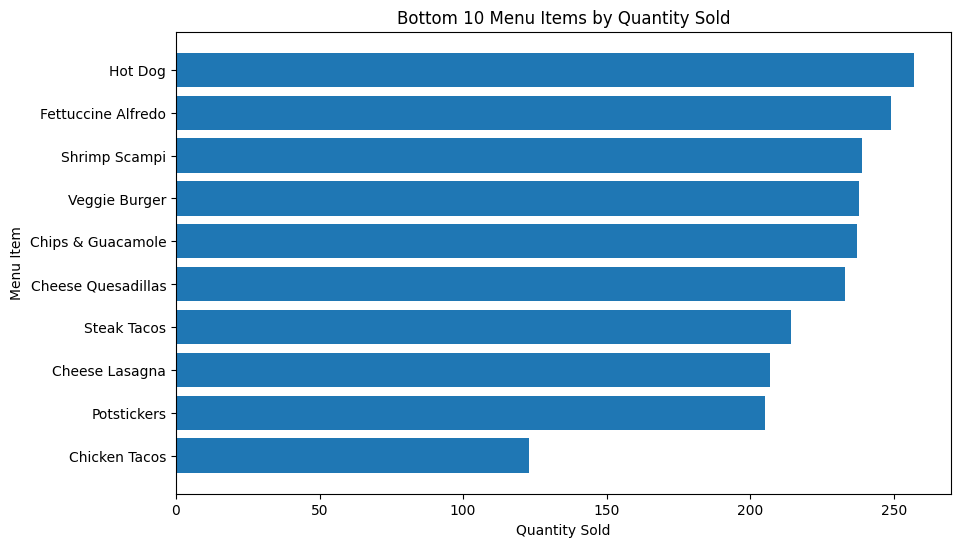

In [24]:
bottom_10_items = low_performing_items.head(10).sort_values('quantity_sold')

plt.figure(figsize=(10, 6))
plt.barh(bottom_10_items['item_name'], bottom_10_items['quantity_sold'])
plt.title('Bottom 10 Menu Items by Quantity Sold')
plt.xlabel('Quantity Sold')
plt.ylabel('Menu Item')
plt.show()

## 11. Day-of-Week Analysis

This section shows which days generate the highest revenue.

In [25]:
weekday_sales = (
    analysis_df.groupby(['day_number', 'day_name'])
    .agg(
        orders=('order_id', 'nunique'),
        items_sold=('order_details_id', 'count'),
        revenue=('revenue', 'sum')
    )
    .reset_index()
    .sort_values('day_number')
)

weekday_sales

,day_number,day_name,orders,items_sold,revenue
0,0,Monday,881,1988,"26,007.45"
1,1,Tuesday,759,1760,"23,356.00"
2,2,Wednesday,680,1522,"19,902.30"
3,3,Thursday,739,1667,"21,846.85"
4,4,Friday,784,1802,"23,707.95"
5,5,Saturday,708,1599,"21,170.90"
6,6,Sunday,792,1759,"23,226.45"


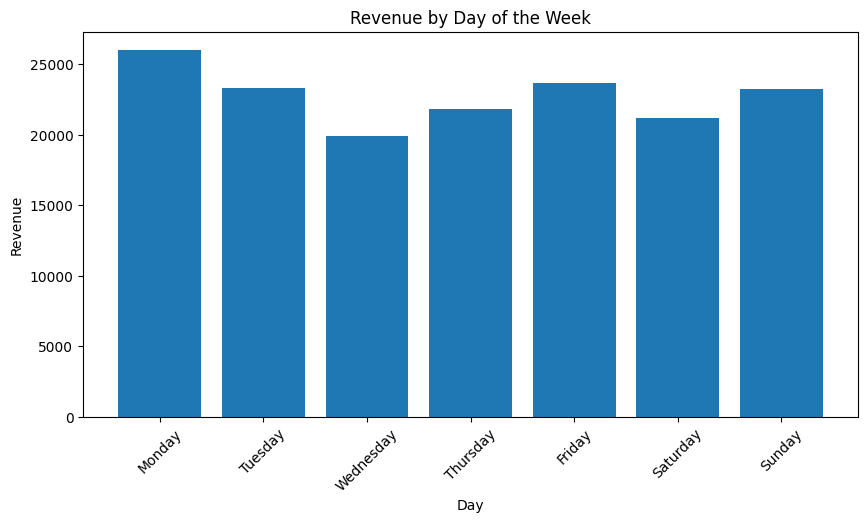

In [26]:
plt.figure(figsize=(10, 5))
plt.bar(weekday_sales['day_name'], weekday_sales['revenue'])
plt.title('Revenue by Day of the Week')
plt.xlabel('Day')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.show()

## 12. Hourly Sales Analysis

This section identifies the busiest and most profitable hours of the day.

In [27]:
hourly_sales = (
    analysis_df.groupby('hour')
    .agg(
        orders=('order_id', 'nunique'),
        items_sold=('order_details_id', 'count'),
        revenue=('revenue', 'sum')
    )
    .reset_index()
    .sort_values('hour')
)

hourly_sales

,hour,orders,items_sold,revenue
0,10,2,5,63.35
1,11,286,624,"8,122.50"
2,12,644,1659,"21,718.40"
3,13,590,1558,"20,640.25"
4,14,423,956,"12,615.70"
5,15,354,743,"9,803.90"
6,16,479,1035,"13,711.65"
7,17,618,1355,"17,869.50"
8,18,595,1290,"16,861.50"
9,19,497,1074,"14,172.60"


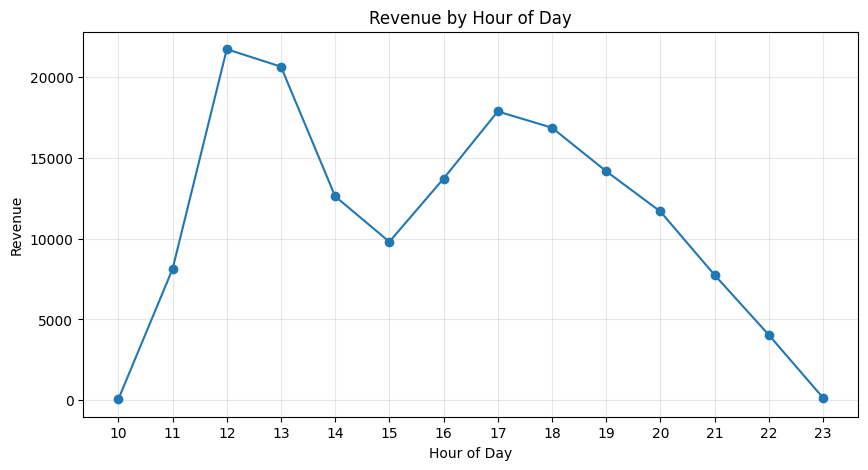

In [28]:
plt.figure(figsize=(10, 5))
plt.plot(hourly_sales['hour'], hourly_sales['revenue'], marker='o')
plt.title('Revenue by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Revenue')
plt.xticks(hourly_sales['hour'])
plt.grid(True, alpha=0.3)
plt.show()

### Peak Period Insight

Hourly analysis helps identify lunch and dinner rush periods. These periods are important for staffing, inventory planning, and targeted promotions.

## 13. Weekday and Hour Heatmap

This heatmap shows sales patterns across weekdays and hours. Darker or lighter areas represent different revenue levels depending on the plotting scale.

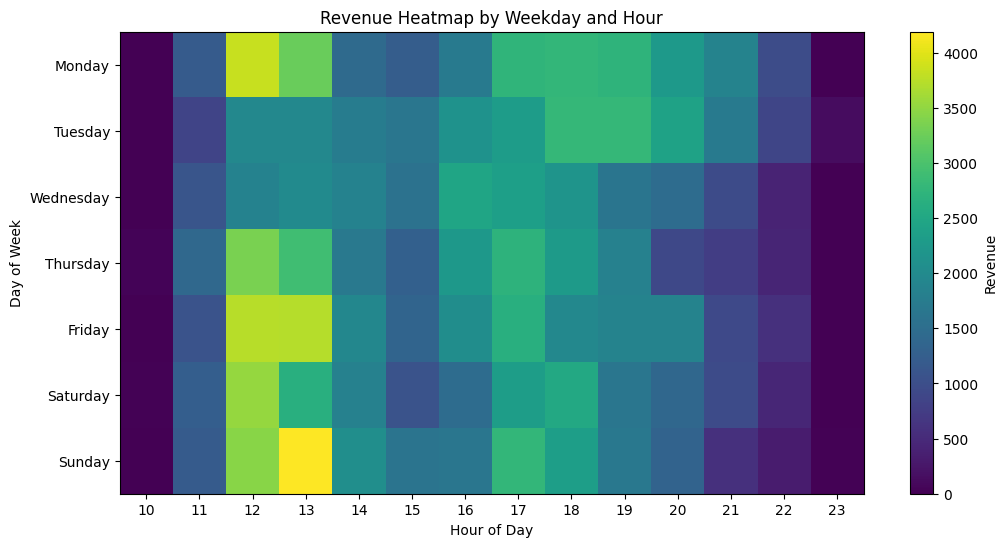

In [29]:
heatmap_data = analysis_df.pivot_table(
    index='day_name',
    columns='hour',
    values='revenue',
    aggfunc='sum',
    fill_value=0
)

# Reorder weekdays
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
heatmap_data = heatmap_data.reindex(weekday_order)

plt.figure(figsize=(12, 6))
plt.imshow(heatmap_data, aspect='auto')
plt.title('Revenue Heatmap by Weekday and Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Day of Week')
plt.xticks(range(len(heatmap_data.columns)), heatmap_data.columns)
plt.yticks(range(len(heatmap_data.index)), heatmap_data.index)
plt.colorbar(label='Revenue')
plt.show()

## 14. Order-Level Analysis

This section calculates order value and number of items per order.

In [30]:
order_level = (
    analysis_df.groupby('order_id')
    .agg(
        order_datetime=('order_datetime', 'min'),
        items_in_order=('order_details_id', 'count'),
        order_value=('revenue', 'sum')
    )
    .reset_index()
)

order_level.head()

,order_id,order_datetime,items_in_order,order_value
0,1,2023-01-01 11:38:36,1,17.95
1,2,2023-01-01 11:57:40,5,64.45
2,3,2023-01-01 12:12:28,2,24.90
3,4,2023-01-01 12:16:31,1,12.95
4,5,2023-01-01 12:21:30,1,12.95


In [31]:
order_level[['items_in_order', 'order_value']].describe()

,items_in_order,order_value
count,"5,343.00","5,343.00"
mean,2.26,29.80
std,1.67,22.66
min,1.00,5.00
25%,1.00,14.95
50%,2.00,24.90
75%,3.00,38.85
max,14.00,192.15


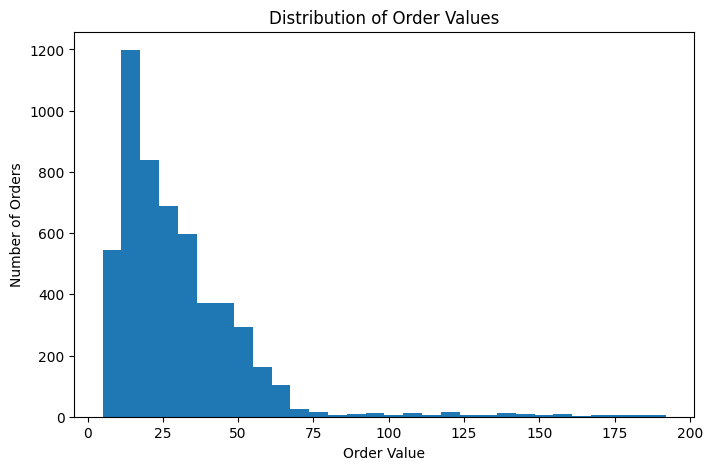

In [32]:
plt.figure(figsize=(8, 5))
plt.hist(order_level['order_value'], bins=30)
plt.title('Distribution of Order Values')
plt.xlabel('Order Value')
plt.ylabel('Number of Orders')
plt.show()

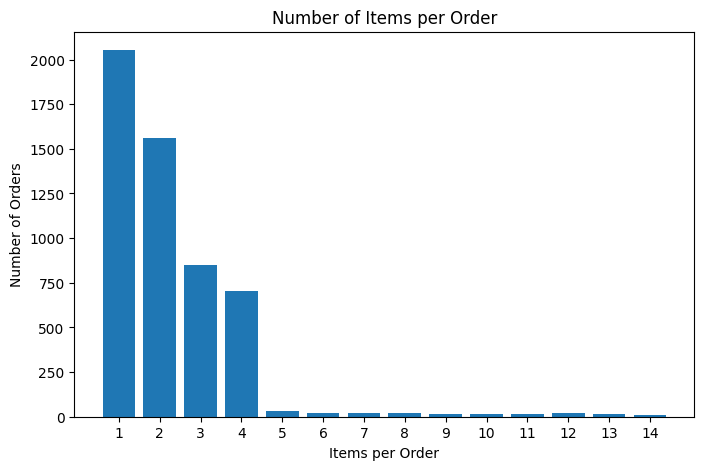

In [33]:
items_per_order = order_level['items_in_order'].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(items_per_order.index.astype(str), items_per_order.values)
plt.title('Number of Items per Order')
plt.xlabel('Items per Order')
plt.ylabel('Number of Orders')
plt.show()

## 15. Basket Analysis: Items Bought Together

Basket analysis helps identify items that customers commonly buy together. This can support combo deals, cross-selling, and menu promotion strategies.

In [34]:
# Get unique item names per order
order_items = (
    analysis_df.groupby('order_id')['item_name']
    .apply(lambda x: sorted(set(x)))
    .reset_index()
)

# Generate all item pairs per order
pair_counts = {}

for items in order_items['item_name']:
    for pair in combinations(items, 2):
        pair_counts[pair] = pair_counts.get(pair, 0) + 1

basket_pairs = (
    pd.DataFrame([
        {'item_1': pair[0], 'item_2': pair[1], 'times_bought_together': count}
        for pair, count in pair_counts.items()
    ])
    .sort_values('times_bought_together', ascending=False)
    .reset_index(drop=True)
)

basket_pairs.head(15)

,item_1,item_2,times_bought_together
0,Edamame,Hamburger,78
1,Cheeseburger,Edamame,75
2,Cheeseburger,Hamburger,72
3,Edamame,Korean Beef Bowl,68
4,French Fries,Korean Beef Bowl,66
5,Cheeseburger,Steak Torta,65
6,Cheeseburger,French Fries,63
7,Chips & Salsa,Edamame,62
8,Hamburger,Korean Beef Bowl,61
9,French Fries,Hamburger,61


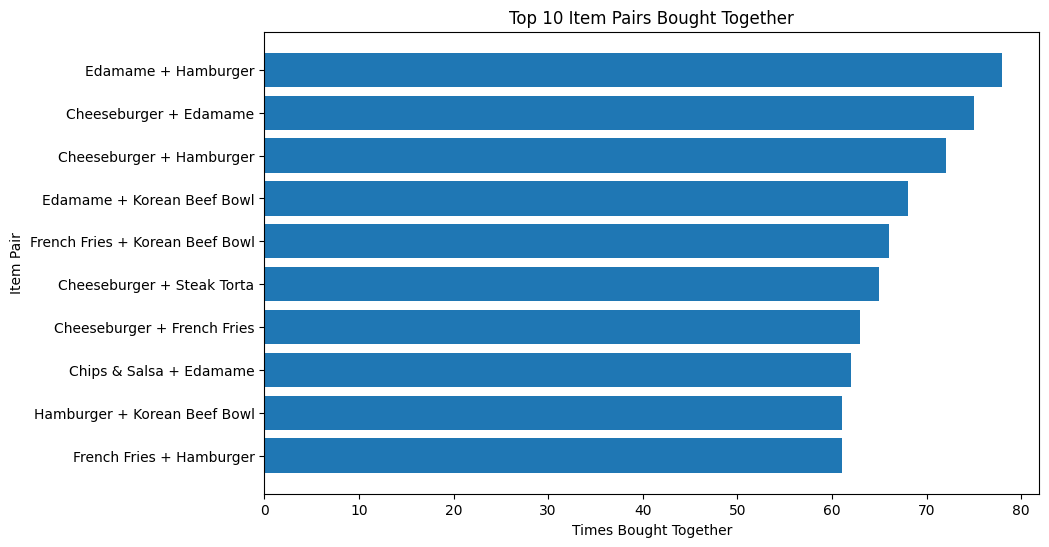

In [35]:
top_basket_pairs = basket_pairs.head(10).copy()
top_basket_pairs['pair'] = top_basket_pairs['item_1'] + ' + ' + top_basket_pairs['item_2']
top_basket_pairs = top_basket_pairs.sort_values('times_bought_together')

plt.figure(figsize=(10, 6))
plt.barh(top_basket_pairs['pair'], top_basket_pairs['times_bought_together'])
plt.title('Top 10 Item Pairs Bought Together')
plt.xlabel('Times Bought Together')
plt.ylabel('Item Pair')
plt.show()

## 16. Business Insights Summary

Based on the analysis, the following insights can be included in the final project report:

1. **Revenue and order performance:** The restaurant generated measurable revenue across the selected period, with average order value showing how much customers spend per order.
2. **Category performance:** Some categories generated more revenue even when they did not sell the highest number of items. This shows the effect of pricing.
3. **Menu performance:** The most sold items are not always the highest revenue items. Revenue analysis is therefore more useful for business decisions than quantity alone.
4. **Peak sales periods:** Lunch and dinner hours are important periods for staffing and food preparation.
5. **Low-performing items:** Items with low quantity sold may need recipe improvement, price review, better promotion, or removal from the menu.
6. **Basket analysis:** Frequently bought-together items can be turned into combo offers to increase sales.
7. **Data quality:** Some order rows had missing item IDs, which means not every order item could be linked to menu details.

## 17. Business Recommendations

1. **Promote high-revenue items:** Menu items that generate high revenue should be made more visible on the menu and in promotions.
2. **Create combo deals:** Items frequently bought together can be bundled into combo offers.
3. **Review low-performing items:** Items with consistently low sales should be investigated. The restaurant can improve them, discount them, or remove them.
4. **Prepare for peak hours:** More staff and inventory should be available during lunch and dinner rush periods.
5. **Use category insights:** Categories with strong revenue performance should receive more attention in marketing and menu planning.
6. **Improve data collection:** Missing item IDs should be fixed in future order records so revenue and product analysis can be more accurate.

## 18. Export Cleaned Data for Power BI

The cleaned dataset and summary tables can be exported as CSV files. These files can later be imported into Power BI for dashboard creation.

In [36]:
output_dir = repo_root / 'data' / 'processed'
output_dir.mkdir(parents=True, exist_ok=True)

# Export cleaned row-level data
analysis_df.to_csv(output_dir / 'restaurant_order_analysis_cleaned.csv', index=False)

# Export useful summary tables
category_performance.to_csv(output_dir / 'category_performance_summary.csv', index=False)
top_items_quantity.to_csv(output_dir / 'menu_item_quantity_summary.csv', index=False)
top_items_revenue.to_csv(output_dir / 'menu_item_revenue_summary.csv', index=False)
weekday_sales.to_csv(output_dir / 'weekday_sales_summary.csv', index=False)
hourly_sales.to_csv(output_dir / 'hourly_sales_summary.csv', index=False)
basket_pairs.to_csv(output_dir / 'basket_analysis_item_pairs.csv', index=False)

print('Files exported successfully.')

Files exported successfully.


## 19. Conclusion

This project shows how restaurant transaction data can be used to understand business performance. The analysis covers sales trends, category performance, menu item performance, customer ordering behavior, peak sales periods, and basket analysis.

The insights from this notebook can help restaurant management make better decisions about menu optimization, staffing, promotions, and revenue growth.